# 04 – Effort correction

Correct the parakeet range for recording effort, using widespread resident bird species as benchmarks.

## Method

At 10 km resolution, the benchmark species occur in essentially every UK square and their range has been stable. So "a benchmark was recorded in square X in year t" is treated as "square X was visited by bird recorders in year t".

Range index per year:

$$\text{range index}(t) = \frac{|\text{parakeet squares}(t) \cap \text{visited squares}(t)|}{|\text{visited squares}(t)|}$$

where *visited squares(t)* are the 10 km squares with at least one record of any benchmark species in year t. Only presence per square and year is used, never record counts.

**Benchmark species** (resident, common in gardens and towns, recorded in the same places as parakeets):
- Wren (*Troglodytes troglodytes*)
- Robin (*Erithacus rubecula*)
- Blackbird (*Turdus merula*)
- Blue Tit (*Cyanistes caeruleus*)

## Steps

1. Download benchmark records from GBIF and NBN Atlas with the same filters as the parakeet download (this notebook first checks how large the downloads will be).
2. Clean them with the same filters as the parakeet data (`src/pipeline.py`).
3. Assign all records to 10 km British National Grid squares.
4. Build square × year presence tables for parakeets and each benchmark.
5. Compute the range index per year, with any benchmark defining "visited".
6. Sensitivity checks: each benchmark separately; parakeet-only squares (dropped vs counted as visited); number of visited squares per year; a fixed set of regularly visited squares.
7. Exclude 2026 (incomplete) and flag the last 1–2 years (NBN Atlas lag).
8. For the sparse early decades, pooled periods (e.g. 5 years) with binomial confidence intervals.
9. Validation against the BTO Bird Atlas periods (1968–72, 1988–91, 2007–11) and published BBS trends, where available.

## Known caveats

- Common species are under-recorded in casual data. Complete-list schemes (BirdTrack, eBird) increased benchmark recording after about 2010, which may overstate recent effort.
- Some data sources only record invasive or notable species (e.g. "INNS Data", "BRERC Notable Species"). They record parakeets but never benchmarks, which creates parakeet-only squares.
- Visited squares are not a random sample: early on they are mostly near towns, where parakeets also are, which may overstate the early index.
- Few visited squares before about 1990, so early index values are noisy.
- Benchmark range is assumed stable at 10 km; to be checked against Bird Atlas maps.

Choices are logged in `decisions.md`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

sys.path.insert(0, "../src")  # shared helpers in src/
from grid import gb_land_hectads, hectad_from_gridref, load_countries
from pipeline import FIRST_YEAR

RECORDS_PATH = "../data/processed/records.parquet"
NBN_API_PATH = Path("../data/processed/nbn_squares_api.csv.gz")             # src/build_nbn_squares.py
GBIF_BENCH_PATH = Path("../data/processed/gbif_benchmark_squares.csv.gz")   # src/build_gbif_benchmarks.py
LAND_PATH = Path("../data/external/ne_10m_admin_0_countries.zip")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")

LAST_YEAR = 2025  # 2026 is incomplete (downloaded in November)

BENCHMARKS = {
    "Wren": "Troglodytes troglodytes",
    "Robin": "Erithacus rubecula",
    "Blackbird": "Turdus merula",
    "Blue Tit": "Cyanistes caeruleus",
}
PARAKEET = "Psittacula krameri"         # used to check the queries against the known download sizes
PARAKEET_LABEL = "Ring-necked Parakeet"  # species label in the square tables

In [2]:
# Parakeet records (merged and filtered, with 10 km squares), from src/build_records.py
records = pd.read_parquet(RECORDS_PATH)
nbn_parakeet = records[records["source"] == "NBN"]
print(f"{len(records):,} parakeet records, of which {len(nbn_parakeet):,} from NBN")

433,993 parakeet records, of which 243,079 from NBN


## Step 1a: how large will the benchmark downloads be?

Before requesting the downloads, count the records per species and year with the GBIF and NBN Atlas search APIs. These return counts only, no records.

Each query is first run for the parakeet, so the result can be compared with the known download sizes (GBIF 192,792, NBN 243,105 on 10 Nov 2026). Small differences are expected because the databases keep growing; a large difference means the query doesn't match the download filters.

In [3]:
# --- GBIF ---
# Same filters as the parakeet download: United Kingdom, has coordinates, no geospatial issues
GBIF_FILTERS = {"country": "GB", "hasCoordinate": "true", "hasGeospatialIssue": "false"}


def gbif_taxon_key(name):
    """Look up the GBIF taxon key for a scientific name, and show what it matched."""
    m = requests.get("https://api.gbif.org/v1/species/match", params={"name": name}, timeout=30).json()
    print(f"  {name} -> {m.get('scientificName')} (key {m.get('usageKey')}, {m.get('matchType')}, {m.get('status')})")
    return m["usageKey"]


def gbif_counts_per_year(name):
    """Number of GBIF records per year for one species, with the download filters."""
    params = {**GBIF_FILTERS, "taxonKey": gbif_taxon_key(name),
              "facet": "year", "facetLimit": 300, "limit": 0}
    r = requests.get("https://api.gbif.org/v1/occurrence/search", params=params, timeout=60).json()
    per_year = pd.Series({int(f["name"]): f["count"] for f in r["facets"][0]["counts"]})
    return r["count"], per_year.sort_index()


print("GBIF taxon matches:")
gbif_total, gbif_years = {}, {}
for label, name in {"Ring-necked Parakeet": PARAKEET, **BENCHMARKS}.items():
    gbif_total[label], gbif_years[label] = gbif_counts_per_year(name)

print(f"\nParakeet check: {gbif_total['Ring-necked Parakeet']:,} now vs 192,792 in the download")

GBIF taxon matches:
  Psittacula krameri -> Psittacula krameri (Scopoli, 1769) (key 2479226, EXACT, ACCEPTED)
  Troglodytes troglodytes -> Troglodytes troglodytes (Linnaeus, 1758) (key 5231438, EXACT, ACCEPTED)
  Erithacus rubecula -> Erithacus rubecula (Linnaeus, 1758) (key 2492462, EXACT, ACCEPTED)
  Turdus merula -> Turdus merula Linnaeus, 1758 (key 2490719, EXACT, ACCEPTED)
  Cyanistes caeruleus -> Cyanistes caeruleus (Linnaeus, 1758) (key 2487879, EXACT, ACCEPTED)

Parakeet check: 192,796 now vs 192,792 in the download


In [4]:
# --- NBN Atlas ---
# The NBN Atlas search API (biocache). Field names are less certain than for GBIF,
# so the parakeet count is the check that the query works as intended.


def nbn_counts_per_year(name):
    """Number of NBN Atlas records per year for one species."""
    params = {"q": f'taxon_name:"{name}"', "facets": "year", "flimit": 300, "pageSize": 0}
    r = requests.get("https://records-ws.nbnatlas.org/occurrences/search", params=params, timeout=60).json()
    results = r.get("facetResults") or []
    year_field = next((f for f in results if f.get("fieldName") == "year"), {"fieldResult": []})
    per_year = pd.Series({int(f["label"]): f["count"]
                          for f in year_field["fieldResult"] if str(f.get("label", "")).isdigit()})
    return r.get("totalRecords"), per_year.sort_index()


nbn_total, nbn_years = {}, {}
for label, name in {"Ring-necked Parakeet": PARAKEET, **BENCHMARKS}.items():
    nbn_total[label], nbn_years[label] = nbn_counts_per_year(name)

print(f"Parakeet check: {nbn_total['Ring-necked Parakeet']:,} now vs 243,105 in the download")

Parakeet check: 255,871 now vs 243,105 in the download


In [5]:
# Where does the NBN parakeet difference (search API vs our download) come from?
# Concentrated in 2025-2026: new records since the download. Spread over all years: the
# search counts records that the download leaves out.
by_year = pd.DataFrame({
    "API now": nbn_years["Ring-necked Parakeet"],
    "our download": nbn_parakeet.groupby("year").size(),
}).fillna(0).astype(int)
by_year["difference"] = by_year["API now"] - by_year["our download"]

print(f"Total difference: {by_year['difference'].sum():,}")
by_year[by_year["difference"].abs() > 50]

Total difference: 12,792


,API now,our download,difference
1996,115,60,55
1998,137,72,65
2000,208,149,59
2001,213,155,58
2002,363,290,73
2003,847,754,93
2004,1241,1165,76
2005,2588,2517,71
2006,2795,2724,71
2007,4993,4927,66


In [6]:
# Totals per species and source, with a rough file size estimate based on the parakeet files:
# GBIF simple CSV ~0.56 KB per record (107.8 MB / 192,792), NBN full Darwin Core ~1.05 KB (255.9 MB / 243,105)
sizes = pd.DataFrame({"GBIF records": pd.Series(gbif_total), "NBN records": pd.Series(nbn_total)})
sizes["GBIF size (GB, est.)"] = (sizes["GBIF records"] * 0.56 / 1e6).round(1)
sizes["NBN size (GB, est.)"] = (sizes["NBN records"] * 1.05 / 1e6).round(1)
sizes.loc["Benchmarks total"] = sizes.drop(index="Ring-necked Parakeet").sum()
sizes

,GBIF records,NBN records,"GBIF size (GB, est.)","NBN size (GB, est.)"
Ring-necked Parakeet,192796,255871,0.1,0.3
Wren,1314286,4762369,0.7,5.0
Robin,1842524,6533767,1.0,6.9
Blackbird,1836632,7052728,1.0,7.4
Blue Tit,1641637,6478949,0.9,6.8
Benchmarks total,6635079,24827813,3.6,26.1


In [7]:
# Records per decade, per species and source: shows how thin the early decades are
def per_decade(per_year_dict):
    table = pd.DataFrame(per_year_dict).fillna(0)
    return table.groupby(table.index // 10 * 10).sum().astype(int).rename_axis("decade")


print("GBIF")
display(per_decade(gbif_years).loc[1960:])
print("NBN Atlas")
display(per_decade(nbn_years).loc[1960:])

GBIF


,Ring-necked Parakeet,Wren,Robin,Blackbird,Blue Tit
decade,,,,,
1960,3,835,1039,1348,1157
1970,32,5585,6691,8443,6768
1980,328,16979,19522,25336,22793
1990,1110,38464,45212,55433,51057
2000,2859,85183,119583,134233,113793
2010,23979,220226,304379,332141,289507
2020,164326,936681,1335884,1269341,1147320


NBN Atlas


,Ring-necked Parakeet,Wren,Robin,Blackbird,Blue Tit
decade,,,,,
1960,17,17798,20545,73023,18527
1970,77,31330,34097,90863,37989
1980,346,96006,98863,165040,106730
1990,820,260202,344900,404006,376641
2000,25593,1214395,1658428,1768233,1701649
2010,98064,1646471,2291032,2450195,2297874
2020,130954,1489677,2077338,2080625,1933281


## Step 1b: NBN visited squares from the API instead of a download (test)

A full NBN download of the benchmarks would be about 25 million records (~26 GB), but the index only needs the list of 10 km squares with a benchmark record in each year. The NBN search API may be able to return exactly that, by counting records per 10 km grid reference (a "facet"), one query per species and year.

Test on the parakeet first: if the squares from the API match the squares in our own NBN data, the API route can be used for the benchmarks.

**First:** find the name of the 10 km grid reference field in the NBN API.

In [8]:
# All fields in the NBN API whose name contains "grid"
fields = requests.get("https://records-ws.nbnatlas.org/index/fields", timeout=60).json()
[f["name"] for f in fields if "grid" in f.get("name", "").lower()]

['gridReference',
 'gridSizeInMeters',
 'grid_ref_100',
 'grid_ref_1000',
 'grid_ref_10000',
 'grid_ref_100000',
 'grid_ref_2000',
 'grid_ref_50000',
 'raw_gridReference',
 'raw_gridSizeInMeters']

In [9]:
GRID_FIELD = "grid_ref_10000"  # change this if the field list above shows a different name
TEST_YEARS = [1988, 2008, 2024]


def nbn_squares(name, year):
    """10 km squares with at least one NBN record of `name` in `year`, from the API facet."""
    params = {"q": f'taxon_name:"{name}"', "fq": f"year:{year}",
              "facets": GRID_FIELD, "flimit": 5000, "pageSize": 0}
    r = requests.get("https://records-ws.nbnatlas.org/occurrences/search", params=params, timeout=60).json()
    results = r.get("facetResults") or []
    field = next((f for f in results if f.get("fieldName") == GRID_FIELD), {"fieldResult": []})
    refs = [f["label"] for f in field["fieldResult"]]
    return refs


rows = []
for year in TEST_YEARS:
    refs = nbn_squares(PARAKEET, year)
    api = {hectad_from_gridref(ref) for ref in refs} - {None}
    ours = set(nbn_parakeet.loc[nbn_parakeet["year"] == year, "hectad"])
    rows.append({
        "year": year,
        "API grid refs": len(refs),
        "not British grid": sum(hectad_from_gridref(ref) is None for ref in refs),
        "API squares": len(api),
        "our squares": len(ours),
        "in both": len(api & ours),
        "API only": len(api - ours),
        "ours only": len(ours - api),
    })
    print(f"{year}: first grid refs from the API: {refs[:5]}")

pd.DataFrame(rows).set_index("year")

1988: first grid refs from the API: ['ST18', 'ST17', 'SK58', 'TQ06', 'TR36']
2008: first grid refs from the API: ['TQ26', 'TQ27', 'TQ47', 'TQ16', 'TQ17']
2024: first grid refs from the API: ['TQ46', 'TQ47', 'TL10', 'TQ36', 'TQ27']


,API grid refs,not British grid,API squares,our squares,in both,API only,ours only
year,,,,,,,
1988,75,0,75,75,75,0,0
2008,219,0,219,211,211,8,0
2024,421,1,420,401,400,20,1


In [10]:
# Which datasets do the extra API records come from? Compare records per dataset for one year.
# Mostly one or two datasets: a data partner reloaded its data on NBN after our download.
# Spread over many datasets: the API includes records the download leaves out.
CHECK_YEAR = 2025

# Name of the dataset field in the API (look for something like "dataResourceName" or "data_resource")
dataset_fields = [f["name"] for f in fields if "resource" in f.get("name", "").lower()]
print("Dataset-like fields:", dataset_fields)
DATASET_FIELD = "data_resource"  # change to a name from the list above if needed

params = {"q": f'taxon_name:"{PARAKEET}"', "fq": f"year:{CHECK_YEAR}",
          "facets": DATASET_FIELD, "flimit": 500, "pageSize": 0}
r = requests.get("https://records-ws.nbnatlas.org/occurrences/search", params=params, timeout=60).json()
facet = next((f for f in (r.get("facetResults") or []) if f.get("fieldName") == DATASET_FIELD), {"fieldResult": []})
api_by_dataset = pd.Series({f["label"]: f["count"] for f in facet["fieldResult"]}, name="API now")

ours_by_dataset = nbn_parakeet.loc[nbn_parakeet["year"] == CHECK_YEAR, "dataset"].value_counts().rename("our download")

compare_datasets = pd.concat([api_by_dataset, ours_by_dataset], axis=1).fillna(0).astype(int)
compare_datasets["difference"] = compare_datasets["API now"] - compare_datasets["our download"]
compare_datasets.sort_values("difference", ascending=False).head(15)

Dataset-like fields: ['dataResourceName', 'dataResourceUid', 'raw_dataResourceName', 'raw_dataResourceUid', 'relatedResourceID', 'relationshipOfResource', 'resourceID', 'resourceRelationshipID']


,API now,our download,difference
Birds (BTO+partners) 2021 - 2023,23979,0,23979
Sheffield and Rotherham Wildlife Trust - Records,14,0,14
INNS Data: All Taxa (South East Wales),16,5,11
Essex Wildlife Trust - Records,5,0,5
INNS records held by BIS in Powys and Brecon Beacons National Park,3,0,3
Bird records via iRecord - unverified records,2,0,2
Nottinghamshire Wildlife Trust - Records,2,0,2
Invasive non-native species records from SEWeb,2,1,1
HNCF BioBlitz and organized survey records from 2023 and 2025,1,0,1
Bird records via iRecord - verified records,43,43,0


The API test matched, so the NBN visited squares come from the API (see `decisions.md`, "Benchmark data from NBN Atlas: API instead of a download"). The download and the API turned out to serve different versions of the BTO data, so the NBN parakeet squares for the index also come from the API ("NBN Atlas download and API serve different data").

## Steps 1–3: data (done by scripts)

- `src/build_nbn_squares.py`: NBN Atlas API, 10 km squares per species and year for the benchmarks and the parakeet → `data/processed/nbn_squares_api.csv.gz`
- `src/build_gbif_benchmarks.py`: GBIF benchmark download (https://doi.org/10.15468/dl.4yeq82), cleaned with `src/pipeline.py`, 10 km squares → `data/processed/gbif_benchmark_squares.csv.gz`
- GBIF parakeet records: `records.parquet` (`src/build_records.py`)

## Step 4: presence tables

One row per species, year and 10 km square with at least one record, combining both sources. Only presence is kept, no record counts.

**Great Britain only** (`decisions.md`, "Recording effort: benchmark species"): squares from Irish grid references are dropped (Northern Ireland and the Republic of Ireland), and so is every square that doesn't touch Great Britain (Northern Ireland squares in the GBIF data, and squares in the sea). Years 1963–2025.

In [11]:
nbn_api = pd.read_csv(NBN_API_PATH)
gbif_bench = pd.read_csv(GBIF_BENCH_PATH)
print(f"NBN API query date: {', '.join(nbn_api['query_date'].unique())}")

# All 10 km squares that touch Great Britain (the denominator for the area later)
gb_squares = gb_land_hectads(load_countries(LAND_PATH))
N_GB_SQUARES = len(gb_squares)
print(f"10 km land squares in Great Britain: {N_GB_SQUARES:,}")

# Irish grid references (one letter, e.g. "J37"): Northern Ireland and Republic of Ireland
irish = nbn_api["gridref"].str.fullmatch(r"[A-HJ-Z]\d+[A-NP-Z]?")
print(f"NBN API rows from Irish grid references (dropped): {irish.sum():,}")

# Combine: NBN API (benchmarks and parakeet), GBIF benchmarks, GBIF parakeet records
all_rows = pd.concat([
    nbn_api.loc[~irish, ["species", "year", "hectad"]].assign(source="NBN API"),
    gbif_bench[["species", "year", "hectad"]].assign(source="GBIF"),
    records.loc[records["source"] == "GBIF", ["year", "hectad"]].assign(species=PARAKEET_LABEL, source="GBIF"),
], ignore_index=True)
all_rows["year"] = all_rows["year"].astype(int)

in_gb = all_rows["hectad"].isin(gb_squares)
in_years = all_rows["year"].between(FIRST_YEAR, LAST_YEAR)
in_scope = in_gb & in_years
print(f"Rows outside Great Britain (Northern Ireland, sea; dropped): {(~in_gb).sum():,}")
print(f"Rows from 2026 (dropped): {(in_gb & ~in_years).sum():,}")
all_rows[~in_gb].groupby(["species", "source"]).size().unstack(fill_value=0)

NBN API query date: 2026-11-11
10 km land squares in Great Britain: 2,843
NBN API rows from Irish grid references (dropped): 26,785
Rows outside Great Britain (Northern Ireland, sea; dropped): 6,290
Rows from 2026 (dropped): 26,732


source,GBIF,NBN API
species,,
Blackbird,1438,382
Blue Tit,1017,90
Ring-necked Parakeet,29,5
Robin,1445,269
Wren,1260,355


In [12]:
# Presence table: one row per species, year and 10 km square (sources combined, presence only)
presence = all_rows[in_scope].drop_duplicates(["species", "year", "hectad"])[["species", "year", "hectad"]]
presence.to_csv(PROCESSED / "presence_10km.csv.gz", index=False)

# Squares per species: over all years, and in a few example years
summary = presence.groupby("species")["hectad"].nunique().rename("all years").to_frame()
for year in [1970, 1990, 2010, LAST_YEAR]:
    summary[year] = presence[presence["year"] == year].groupby("species")["hectad"].nunique()
summary.fillna(0).astype(int)

,all years,1970,1990,2010,2025
species,,,,,
Blackbird,2793,695,1145,2620,2594
Blue Tit,2689,399,966,2472,2446
Ring-necked Parakeet,1136,2,35,189,543
Robin,2784,354,916,2624,2624
Wren,2798,204,797,2624,2650


## Step 5: range index

For each year: the share of visited squares (any benchmark recorded) that also have a parakeet record. Converted to an estimated occupied area (index × number of GB land squares × 100 km²), and compared with the uncorrected area from the same inputs. If the correction works, the jumps in the atlas years (shaded) should largely disappear from the corrected curve.

The last two years are flagged as possibly incomplete (NBN Atlas lag).

In [13]:
def squares_per_year(species):
    """Set of 10 km squares per year for the given species (a list of labels)."""
    sel = presence[presence["species"].isin(species)]
    return sel.groupby("year")["hectad"].agg(set)


years = range(FIRST_YEAR, LAST_YEAR + 1)
visited = squares_per_year(list(BENCHMARKS))   # any benchmark = visited
parakeet = squares_per_year([PARAKEET_LABEL])

rows = []
for year in years:
    v = visited.get(year, set())
    p = parakeet.get(year, set())
    rows.append({
        "year": year,
        "visited": len(v),                      # squares with any benchmark record
        "parakeet": len(p),                     # squares with a parakeet record
        "parakeet_and_visited": len(p & v),
        "parakeet_only": len(p - v),            # parakeet recorded, no benchmark (step 6)
        "index": len(p & v) / len(v) if v else np.nan,
    })
range_index = pd.DataFrame(rows).set_index("year")

# Index -> estimated occupied area: the area if every GB square had been visited
range_index["area_corrected_km2"] = range_index["index"] * N_GB_SQUARES * 100
range_index["sqrt_area_corrected"] = np.sqrt(range_index["area_corrected_km2"])
# Uncorrected area from the same inputs, for comparison
range_index["area_uncorrected_km2"] = range_index["parakeet"] * 100
range_index["sqrt_area_uncorrected"] = np.sqrt(range_index["area_uncorrected_km2"])
# Step 7: NBN Atlas data for the last years may still be incomplete
range_index["possibly_incomplete"] = range_index.index >= LAST_YEAR - 1

range_index.to_csv(PROCESSED / "range_index.csv")
range_index.round(3)

,visited,parakeet,parakeet_and_visited,parakeet_only,index,area_corrected_km2,sqrt_area_corrected,area_uncorrected_km2,sqrt_area_uncorrected,possibly_incomplete
year,,,,,,,,,,
1963,750,1,1,0,0.001,379.067,19.470,100,10.000,False
1964,776,1,1,0,0.001,366.366,19.141,100,10.000,False
1965,845,0,0,0,0.000,0.000,0.000,0,0.000,False
1966,812,0,0,0,0.000,0.000,0.000,0,0.000,False
1967,819,2,2,0,0.002,694.261,26.349,200,14.142,False
...,...,...,...,...,...,...,...,...,...,...
2021,2654,414,414,0,0.156,44348.229,210.590,41400,203.470,False
2022,2678,398,398,0,0.149,42252.203,205.553,39800,199.499,False
2023,2696,449,449,0,0.167,47348.182,217.596,44900,211.896,False


In [ ]:
# √(area) against year: effort-corrected vs uncorrected (same inputs, so only the correction differs)
CORRECTED = "#2a78d6"    # blue
UNCORRECTED = "#eb6834"  # orange
TEXT, MUTED, GRID, SHADE = "#333333", "#898781", "#e1e0d9", "#f0efec"
ATLASES = [(1981, 1984, "Winter\nAtlas"), (1988, 1991, "Breeding\nAtlas"), (2007, 2011, "Bird Atlas\n2007–11")]

fig, ax = plt.subplots(figsize=(9, 5))
for start, end, label in ATLASES:
    ax.axvspan(start - 0.5, end + 0.5, color=SHADE, zorder=0)
    ax.text((start + end) / 2, 0.98, label, transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=7, color=MUTED)

for col, colour, label in [("sqrt_area_corrected", CORRECTED, "Effort-corrected"),
                           ("sqrt_area_uncorrected", UNCORRECTED, "Uncorrected")]:
    ax.plot(range_index.index, range_index[col], color=colour, linewidth=2, label=label)

ax.set_xlabel("Year")
ax.set_ylabel("√ occupied area (km)")
ax.set_title("Parakeet range in Great Britain, 10 km squares")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.9))
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "range_corrected_vs_uncorrected.png", dpi=200)

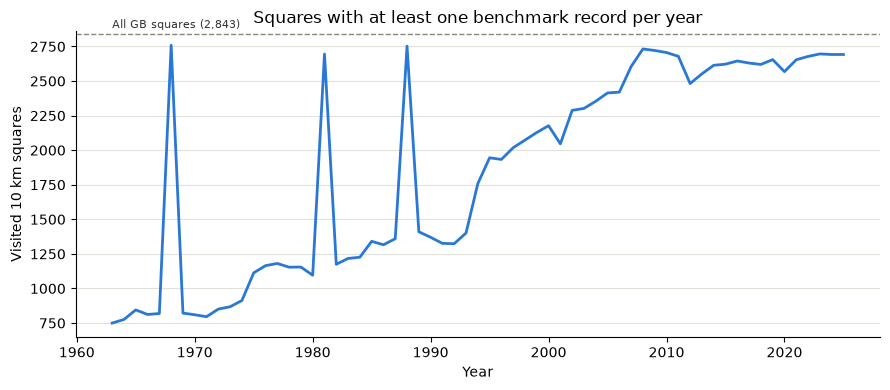

In [15]:
# Number of 10 km squares with records per year (visited by bird recorders), against all GB squares
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range_index.index, range_index["visited"], color="#2a78d6", linewidth=2)
ax.axhline(N_GB_SQUARES, color=MUTED, linewidth=1, linestyle="--")
ax.annotate(f"All GB squares ({N_GB_SQUARES:,})", (range_index.index[0], N_GB_SQUARES),
            xytext=(0, 4), textcoords="offset points", fontsize=8, color=TEXT)

ax.set_xlabel("Year")
ax.set_ylabel("Visited 10 km squares")
ax.set_title("Squares with at least one benchmark record per year")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "visited_squares_per_year.png", dpi=200)

## Spread rate

Following Skellam (1951): the slope of √(area) against year, from a straight-line fit. Two ways to report it:

- **√area per year (km):** the slope itself.
- **Radial spread (km per year):** for a circular range, radius = √(area / π), so the radius grows by slope / √π per year. This is the usual "spread rate".

Fitted for the whole period (1970–2025) and for two phases: 1970–2009, with a roughly constant slope, and 2010–2025, with a steeper one. The phases are set from the plot, not estimated from the data; 2010 also marks the start of almost complete coverage (see the visited-squares plot). The atlas start years (1968, 1981, 1988) are left out, because each contains a whole multi-year atlas. Years before 1970 have too few records for a fit.

**Uncertainty:** ± 2 standard errors of the slope, roughly a 95% interval. Consecutive years are not independent, so the true uncertainty is larger than this.

**Limitation:** the correction covers which squares were visited (coverage), not how thoroughly (intensity). From about 2008 nearly all squares are visited every year, so the correction is small there and the recent rate may still include part of the growth in recording (eBird). The checks below test this. See `decisions.md`.

In [ ]:
PERIODS = [(1970, 2025), (1970, 2009), (2010, 2025)]
ATLAS_START_YEARS = [1968, 1981, 1988]  # whole atlas dated to its first year: left out of the fits


def fit_line(series, start, end):
    """Straight-line fit of `series` over the years start-end, leaving out the atlas years.

    Returns slope, standard error of the slope, intercept and number of years used.
    """
    s = series.loc[start:end].drop(ATLAS_START_YEARS, errors="ignore").dropna()
    x, y = s.index.to_numpy(dtype=float), s.to_numpy(dtype=float)
    slope, intercept = np.polyfit(x, y, 1)
    residuals = y - (slope * x + intercept)
    se = np.sqrt((residuals ** 2).sum() / (len(x) - 2) / ((x - x.mean()) ** 2).sum())
    return slope, se, intercept, len(x)


rows = []
for start, end in PERIODS:
    for measure, col in [("corrected", "sqrt_area_corrected"), ("uncorrected", "sqrt_area_uncorrected")]:
        slope, se, _, n = fit_line(range_index[col], start, end)
        rows.append({
            "period": f"{start}–{end}",
            "measure": measure,
            "years used": n,
            "√area per year (km)": slope,
            "± 2 SE": 2 * se,
            "radial spread (km/yr)": slope / np.sqrt(np.pi),   # radius = √(area / π)
            "radial ± 2 SE": 2 * se / np.sqrt(np.pi),
        })
spread_rates = pd.DataFrame(rows)
spread_rates.to_csv(PROCESSED / "spread_rates.csv", index=False)
spread_rates.round(2)

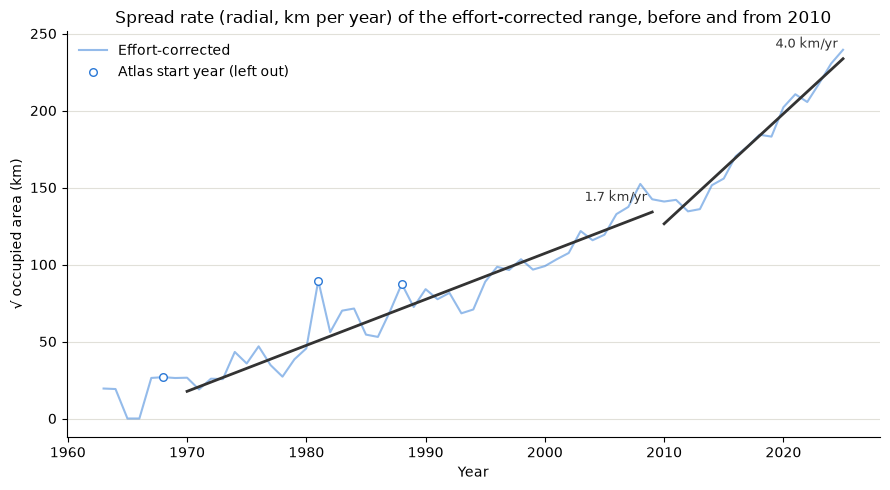

In [26]:
# Effort-corrected √(area) with the fitted lines for the two phases, before and from 2010
TWO_PHASES = [(1970, 2009), (2010, 2025)]

fig, ax = plt.subplots(figsize=(9, 5))
used = ~range_index.index.isin(ATLAS_START_YEARS)
ax.plot(range_index.index, range_index["sqrt_area_corrected"], color=CORRECTED, linewidth=1.5,
        alpha=0.5, label="Effort-corrected")
ax.scatter(range_index.index[~used], range_index.loc[~used, "sqrt_area_corrected"],
           facecolors="white", edgecolors=CORRECTED, s=30, zorder=3, label="Atlas start year (left out)")

for start, end in TWO_PHASES:
    slope, _, intercept, _ = fit_line(range_index["sqrt_area_corrected"], start, end)
    x = np.array([start, end])
    ax.plot(x, slope * x + intercept, color=TEXT, linewidth=2)
    ax.annotate(f"{slope / np.sqrt(np.pi):.1f} km/yr", (end, slope * end + intercept),
                xytext=(-4, 8), textcoords="offset points", ha="right", fontsize=9, color=TEXT)

ax.set_xlabel("Year")
ax.set_ylabel("√ occupied area (km)")
ax.set_title("Spread rate (radial, km per year) of the effort-corrected range, before and from 2010")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "spread_rate_by_period.png", dpi=200)

## Is the acceleration after 2010 real, or more recording?

The spread rate is about 1.7 km/yr until 2009 and about 4 km/yr from 2010. From 2010 nearly every square is visited each year, so the benchmark correction can't remove the growth in recording intensity (especially eBird). Two checks with the data already in hand:

1. **NBN only:** the index from NBN data alone, for parakeets and benchmarks. NBN does not include eBird. If the acceleration remains, it is probably not an eBird effect.
2. **Persistent squares:** a parakeet square counts in a year only if parakeets were also recorded there the year before or after. One-off sightings (wandering birds, single visits) drop out. If the acceleration remains, the parakeets are really settling in new areas.

Both are compared with the main index as two-phase spread rates (1970–2009 and 2010–2025).

In [27]:
def index_table(pres, parakeet_sets=None):
    """Range index per year from a presence table (species, year, hectad).

    Visited = squares with any benchmark. Parakeet squares come from `pres`, unless a
    Series of sets per year is given (`parakeet_sets`).
    """
    visited_sets = pres[pres["species"].isin(list(BENCHMARKS))].groupby("year")["hectad"].agg(set)
    if parakeet_sets is None:
        parakeet_sets = pres[pres["species"] == PARAKEET_LABEL].groupby("year")["hectad"].agg(set)
    rows = []
    for year in years:
        v, p = visited_sets.get(year, set()), parakeet_sets.get(year, set())
        rows.append({"year": year, "visited": len(v), "parakeet": len(p),
                     "index": len(p & v) / len(v) if v else np.nan})
    table = pd.DataFrame(rows).set_index("year")
    table["sqrt_area_corrected"] = np.sqrt(table["index"] * N_GB_SQUARES * 100)
    return table


variants = {"Main (all data)": index_table(presence)}

# Check 1: NBN only. No GBIF data at all, so no eBird, for parakeets and benchmarks alike
nbn_only = (all_rows[in_scope & (all_rows["source"] == "NBN API")]
            .drop_duplicates(["species", "year", "hectad"]))
variants["NBN only"] = index_table(nbn_only)

# Check 2: persistent squares. A parakeet square counts in year t only if it also has a
# parakeet record in t-1 or t+1. Drops one-off sightings (wandering birds, single visits).
# Note: in the first and last year only one neighbouring year exists, so they are stricter.
parakeet_sets = presence[presence["species"] == PARAKEET_LABEL].groupby("year")["hectad"].agg(set)
persistent_sets = pd.Series({
    year: {sq for sq in parakeet_sets.get(year, set())
           if sq in parakeet_sets.get(year - 1, set()) or sq in parakeet_sets.get(year + 1, set())}
    for year in years
})
variants["Persistent squares"] = index_table(presence, persistent_sets)

# Two-phase spread rates for each variant
rows = []
for name, table in variants.items():
    for start, end in [(1970, 2009), (2010, 2025)]:
        slope, se, _, n = fit_line(table["sqrt_area_corrected"], start, end)
        rows.append({"variant": name, "period": f"{start}–{end}", "years used": n,
                     "radial spread (km/yr)": slope / np.sqrt(np.pi),
                     "radial ± 2 SE": 2 * se / np.sqrt(np.pi)})
acceleration = pd.DataFrame(rows)
acceleration.to_csv(PROCESSED / "spread_rates_checks.csv", index=False)

# Ratio of the later to the earlier rate: > 1 means the spread speeds up
ratio = (acceleration.pivot(index="variant", columns="period", values="radial spread (km/yr)")
         .assign(ratio=lambda t: t["2010–2025"] / t["1970–2009"]))
display(acceleration.round(2))
ratio.round(2)

,variant,period,years used,radial spread (km/yr),radial ± 2 SE
0,Main (all data),1970–2009,38,1.68,0.14
1,Main (all data),2010–2025,16,4.03,0.44
2,NBN only,1970–2009,38,1.74,0.17
3,NBN only,2010–2025,16,3.39,0.39
4,Persistent squares,1970–2009,38,1.37,0.14
5,Persistent squares,2010–2025,16,4.03,0.33


period,1970–2009,2010–2025,ratio
variant,,,
Main (all data),1.68,4.03,2.39
NBN only,1.74,3.39,1.95
Persistent squares,1.37,4.03,2.94


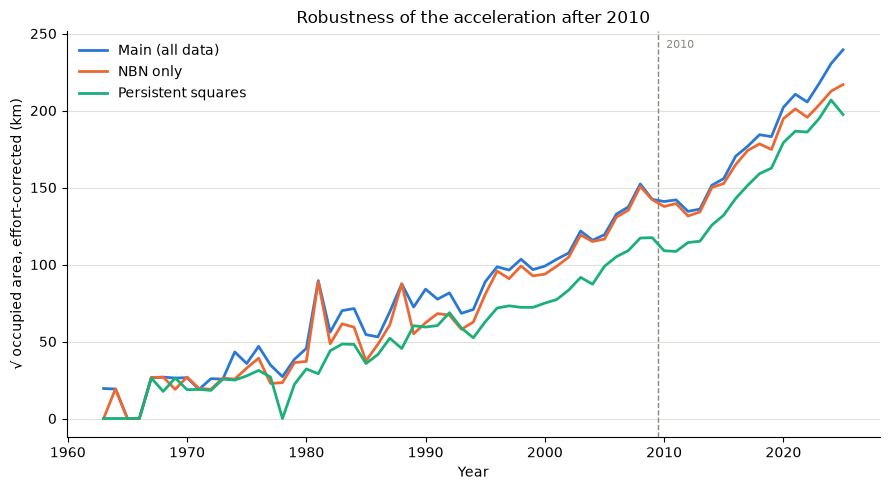

In [28]:
# The three variants together: does the steeper rise after 2010 remain?
VARIANT_COLOURS = {"Main (all data)": "#2a78d6", "NBN only": "#eb6834", "Persistent squares": "#1baf7a"}

fig, ax = plt.subplots(figsize=(9, 5))
ax.axvline(2009.5, color=MUTED, linewidth=1, linestyle="--")
ax.text(2009.5, 0.98, "  2010", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=MUTED)
for name, table in variants.items():
    ax.plot(table.index, table["sqrt_area_corrected"], color=VARIANT_COLOURS[name], linewidth=2, label=name)

ax.set_xlabel("Year")
ax.set_ylabel("√ occupied area, effort-corrected (km)")
ax.set_title("Robustness of the acceleration after 2010")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "acceleration_checks.png", dpi=200)